<a href="https://colab.research.google.com/github/yafetmulaw/fake-news-prediction/blob/main/fake_news_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ***Fake News Prediction***
---

## **Importing libraries**

In [3]:
import numpy as np
import pandas as pd
import re
from nltk.corpus import stopwords
from nltk.stem.porter import PorterStemmer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

**Downloading and reading the stopwords that we're going to remove from the feaure**

In [4]:
from nltk import download
download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [5]:
print(stopwords.words('english'))

['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been', 'before', 'being', 'below', 'between', 'both', 'but', 'by', 'can', 'couldn', "couldn't", 'd', 'did', 'didn', "didn't", 'do', 'does', 'doesn', "doesn't", 'doing', 'don', "don't", 'down', 'during', 'each', 'few', 'for', 'from', 'further', 'had', 'hadn', "hadn't", 'has', 'hasn', "hasn't", 'have', 'haven', "haven't", 'having', 'he', "he'd", "he'll", 'her', 'here', 'hers', 'herself', "he's", 'him', 'himself', 'his', 'how', 'i', "i'd", 'if', "i'll", "i'm", 'in', 'into', 'is', 'isn', "isn't", 'it', "it'd", "it'll", "it's", 'its', 'itself', "i've", 'just', 'll', 'm', 'ma', 'me', 'mightn', "mightn't", 'more', 'most', 'mustn', "mustn't", 'my', 'myself', 'needn', "needn't", 'no', 'nor', 'not', 'now', 'o', 'of', 'off', 'on', 'once', 'only', 'or', 'other', 'our', 'ours', 'ourselves', 'out', 'over', 'own', 're', 's', 'same', 'shan', "shan't", 'she

### **Downloading, converting into DataFrame and an Overview**

In [6]:
import kagglehub
path = kagglehub.dataset_download("bhavikjikadara/fake-news-detection")

Using Colab cache for faster access to the 'fake-news-detection' dataset.


In [8]:
import os

true_df = pd.read_csv(os.path.join(path, "true.csv"))
fake_df = pd.read_csv(os.path.join(path, "fake.csv"))

In [9]:
true_df.head()

,title,text,subject,date
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017"
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017"
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017"
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017"
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017"


In [10]:
fake_df.head()

,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017"
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017"


In [11]:
print(true_df.shape, fake_df.shape)

(21417, 4) (23481, 4)


In [12]:
true_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21417 entries, 0 to 21416
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   title    21417 non-null  object
 1   text     21417 non-null  object
 2   subject  21417 non-null  object
 3   date     21417 non-null  object
dtypes: object(4)
memory usage: 669.4+ KB


In [13]:
fake_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23481 entries, 0 to 23480
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   title    23481 non-null  object
 1   text     23481 non-null  object
 2   subject  23481 non-null  object
 3   date     23481 non-null  object
dtypes: object(4)
memory usage: 733.9+ KB


## **Data Preprocessing and Cleaning**

**Checking Missing Values**

In [14]:
true_df.isnull().sum()

,0
title,0
text,0
subject,0
date,0


In [15]:
fake_df.isnull().sum()

,0
title,0
text,0
subject,0
date,0


**Inserting a column "label" as target feature**

In [16]:
fake_df['label'] = 0
true_df['label'] = 1

In [17]:
true_df.head()

,title,text,subject,date,label
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017",1
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017",1
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017",1
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017",1
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017",1


In [18]:
fake_df.head()

,title,text,subject,date,label
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017",0
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017",0
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017",0
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017",0
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017",0


**Merging True and Fake Dataframes**

In [19]:
df_merged = pd.concat([true_df, fake_df], axis=0)
df_merged.head()

,title,text,subject,date,label
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017",1
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017",1
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017",1
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017",1
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017",1


In [20]:
df_merged.shape

(44898, 5)

In [21]:
df_merged.columns

Index(['title', 'text', 'subject', 'date', 'label'], dtype='object')

**Droping Unnecessary Columns**

In [22]:
df = df_merged.drop(["title", "subject", "date"], axis=1)
df.head()

,text,label
0,WASHINGTON (Reuters) - The head of a conservat...,1
1,WASHINGTON (Reuters) - Transgender people will...,1
2,WASHINGTON (Reuters) - The special counsel inv...,1
3,WASHINGTON (Reuters) - Trump campaign adviser ...,1
4,SEATTLE/WASHINGTON (Reuters) - President Donal...,1


**Random Shuffling of Dataset and Reseting the index**

In [23]:
df = df.sample(frac = 1)
df.head()

,text,label
19223,One California resident commented: Lots of ill...,0
11592,"Speaking to BBC Newsnight in a rare interview,...",0
11370,During a meeting of the Welsh members of the P...,0
6643,WASHINGTON (Reuters) - U.S. Republican and Dem...,1
11326,The London terror attack was a horrific scene ...,0


In [24]:
df.reset_index(inplace = True)
df.drop(["index"], axis = 1, inplace = True)
df.head()

,text,label
0,One California resident commented: Lots of ill...,0
1,"Speaking to BBC Newsnight in a rare interview,...",0
2,During a meeting of the Welsh members of the P...,0
3,WASHINGTON (Reuters) - U.S. Republican and Dem...,1
4,The London terror attack was a horrific scene ...,0


In [25]:
port_stem = PorterStemmer()

### **Text Preprocessing**

In [26]:
def stemming(text):
  stemmed_text = re.sub("[^a-zA-Z]", " ", text)
  stemmed_text = stemmed_text.lower()
  stemmed_text = stemmed_text.split()
  stemmed_text = [port_stem.stem(word) for word in stemmed_text if word not in stopwords.words("english")]
  stemmed_text = ' '.join(stemmed_text)
  return stemmed_text

In [27]:
df["text"] = df["text"].apply(stemming)

In [28]:
df.head()

,text,label
0,one california resid comment lot illeg vote ca...,0
1,speak bbc newsnight rare interview justic gins...,0
2,meet welsh member parliament pm nigel evan sha...,0
3,washington reuter u republican democrat senat ...,1
4,london terror attack horrif scene injur bodi s...,0


**Visualizing the Label**

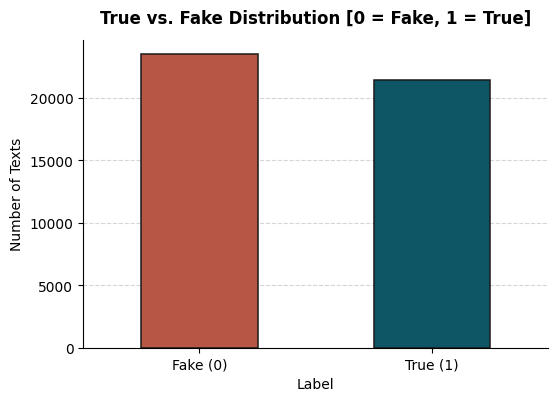

In [29]:
import seaborn as sns
import matplotlib.pyplot as plt

creative_palette = {
    0: "#C84B31",
    1: "#005F73",
}

plt.figure(figsize=(6, 4))
ax = sns.countplot(
    data=df,
    x="label",
    hue="label",
    palette=creative_palette,
    edgecolor="#1A1A1A",
    linewidth=1.1,
    width=0.5,
    legend=False
)

ax.yaxis.grid(True, linestyle="--", alpha=0.35, color="#888888")
ax.set_axisbelow(True)
sns.despine()

plt.title("True vs. Fake Distribution [0 = Fake, 1 = True]", fontsize=12, fontweight="bold", pad=12)
plt.xlabel("Label")
plt.ylabel("Number of Texts")
plt.xticks([0, 1], ['Fake (0)', 'True (1)'])
plt.show()

## **Train-Test Splititng**

In [30]:
X = df['text'].values
y = df['label'].values

In [31]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=2)

## **Converting text to vectors**

In [40]:
vectorizer = TfidfVectorizer()
Xv_train = vectorizer.fit_transform(X_train)
Xv_test = vectorizer.transform(X_test)

Comparing Logistic Regression (a fast, linear baseline assuming independent word contributions) against Gradient Boosting (a non-linear ensemble capturing complex word interactions) to empirically determine which hypothesis space best minimizes generalization error for our text corpus.

## **Logistic Regression**

In [41]:
lr_model = LogisticRegression(random_state=2)
lr_model.fit(Xv_train, y_train)

LogisticRegression(random_state=2)

**Calculating LR Accuracies**

In [42]:
lr_train_acc = lr_model.score(Xv_train, y_train)
lr_test_acc = lr_model.score(Xv_test, y_test)

## **Gradient Boosting Classifier**

In [43]:
gbc_model = GradientBoostingClassifier(random_state=2)
gbc_model.fit(Xv_train, y_train)

GradientBoostingClassifier(random_state=2)

**Calculating GBC Accuracies**

In [44]:
gbc_train_acc = gbc_model.score(Xv_train, y_train)
gbc_test_acc = gbc_model.score(Xv_test, y_test)

**Printing Comparison Table**

In [45]:
print("\n" + "="*40)
print(f"{'Model':<25} | {'Train Accuracy':<15} | {'Test Accuracy':<15}")
print("="*40)
print(f"{'Logistic Regression':<25} | {lr_train_acc*100:.2f}%          | {lr_test_acc*100:.2f}%")
print(f"{'Gradient Boosting':<25} | {gbc_train_acc*100:.2f}%          | {gbc_test_acc*100:.2f}%")
print("="*40 + "\n")


Model                     | Train Accuracy  | Test Accuracy  
Logistic Regression       | 99.07%          | 98.52%
Gradient Boosting         | 99.74%          | 99.44%



In [46]:
if gbc_test_acc >= lr_test_acc:
    best_model = gbc_model
    best_model_name = "Gradient Boosting Classifier"
else:
    best_model = lr_model
    best_model_name = "Logistic Regression"

print(f"--> Best Performing Model Selected for Evaluation: {best_model_name}\n")

--> Best Performing Model Selected for Evaluation: Gradient Boosting Classifier



In [47]:
y_pred_best = best_model.predict(Xv_test)

## **Model Evaluation**

In [48]:
print("Classification Report:\n", classification_report(y_test, y_pred_best))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_best))
print(f"Final Accuracy Score: {accuracy_score(y_test, y_pred_best):.4f}")

Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.99      0.99      4715
           1       0.99      1.00      0.99      4265

    accuracy                           0.99      8980
   macro avg       0.99      0.99      0.99      8980
weighted avg       0.99      0.99      0.99      8980

Confusion Matrix:
 [[4674   41]
 [   9 4256]]
Final Accuracy Score: 0.9944


**Plot Confusion Matrix Heatmap**

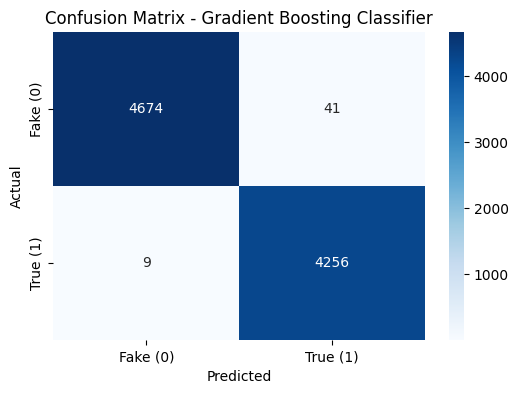

In [49]:
cm = confusion_matrix(y_test, y_pred_best)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Fake (0)', 'True (1)'], yticklabels=['Fake (0)','True (1)'])
plt.title(f'Confusion Matrix - {best_model_name}')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

## **Prediction**

In [50]:
def output_label(n):
    if n == 0:
        return "Fake News"
    elif n == 1:
        return "Not A Fake News (True)"

def manual_testing(news):
    testing_news = {"text": [news]}
    new_def_test = pd.DataFrame(testing_news)

    new_def_test["text"] = new_def_test["text"].apply(stemming)
    new_x_test = new_def_test["text"]

    new_xv_test = vectorizer.transform(new_x_test)

    y_pred = best_model.predict(new_xv_test)

    print(f"\nModel Used: {best_model_name}")
    print(f"Prediction: {output_label(y_pred[0])}")

In [ ]:
news = str(input("Paste news article text here: "))
manual_testing(news)

In [60]:
import joblib
joblib.dump(best_model, "best_fake_news_model.pkl")
joblib.dump(vectorizer, "tfidf_vectorizer.pkl")

['tfidf_vectorizer.pkl']